In [42]:
import os
import re
import pickle
import argparse
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely

from tqdm import tqdm
from shapely.ops import unary_union

import metrics as M  # DO NOT MODIFY THIS FILE

warnings.filterwarnings("ignore")


# ============================
# Helpers
# ============================
def ensure_dir(p: str):
    os.makedirs(p, exist_ok=True)

def union_geoms(geoms):
    geoms = list(geoms)
    if not geoms:
        return None
    if hasattr(shapely, "union_all"):
        return shapely.union_all(geoms)
    return unary_union(geoms)

def seed_from_dir(run_dir: str) -> int:
    base = os.path.basename(run_dir.rstrip("/"))
    if base.startswith("seed_"):
        return int(base.split("_")[1])
    raise ValueError(f"Cannot parse seed from directory: {run_dir}")

def read_geojson(path: str, default_crs: str = "EPSG:4326"):
    """
    Read GeoJSON robustly.
    If CRS is missing, assume EPSG:4326 (lon/lat) for your prediction/GT files.
    """
    gdf = gpd.read_file(path)

    if "geometry" not in gdf.columns:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=default_crs)

    if gdf.crs is None:
        gdf = gdf.set_crs(default_crs, allow_override=True)

    # Ensure geometry active
    try:
        if gdf.geometry.name != "geometry":
            gdf = gdf.set_geometry("geometry")
    except Exception:
        return gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=default_crs)

    return gdf

def buffered_union_geom_in_proj(gdf_ll: gpd.GeoDataFrame):
    """
    Buffer union in M.PROJ units (meters if epsg:26910).
    """
    if gdf_ll is None or len(gdf_ll) == 0:
        return None

    if gdf_ll.crs is None:
        gdf_ll = gdf_ll.set_crs("EPSG:4326", allow_override=True)

    gdf = gdf_ll.to_crs(M.PROJ)

    bufs = []
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        b = geom.buffer(M.BUFF_DIS)
        if b is not None and not b.is_empty:
            bufs.append(b)

    return union_geoms(bufs)

def buffered_iou_from_unions(gt_buf, pred_buf) -> float:
    if gt_buf is None and pred_buf is None:
        return 1.0
    if gt_buf is None or pred_buf is None:
        return 0.0
    inter = float(pred_buf.intersection(gt_buf).area)
    union = float(pred_buf.union(gt_buf).area)
    return float(inter / union) if union > 0 else 0.0


# ============================
# GT discovery (used only to locate GT files if needed)
# ============================
GT_RE = re.compile(r"^(?P<idx>.+)_seed(?P<seed>\d+)_gt\.geojson$")

def build_gt_index(pred_root: str):
    """
    Build mapping idx_str -> any GT geojson path under pred_root.
    (Not strictly needed for eval once cache exists, but useful for sanity.)
    """
    gt_map = {}
    if not os.path.isdir(pred_root):
        return gt_map

    for model_name in os.listdir(pred_root):
        if model_name.startswith("_"):
            continue
        model_dir = os.path.join(pred_root, model_name)
        if not os.path.isdir(model_dir):
            continue

        for tag in ["base", "grpo"]:
            tag_dir = os.path.join(model_dir, tag)
            if not os.path.isdir(tag_dir):
                continue

            for seed_dir in os.listdir(tag_dir):
                if not seed_dir.startswith("seed_"):
                    continue
                run_dir = os.path.join(tag_dir, seed_dir)
                if not os.path.isdir(run_dir):
                    continue

                for fn in os.listdir(run_dir):
                    m = GT_RE.match(fn)
                    if not m:
                        continue
                    idx = m.group("idx")
                    if idx not in gt_map:
                        gt_map[idx] = os.path.join(run_dir, fn)

    return gt_map


# ============================
# Tile measures + aggregation
# ============================
def compute_pred_tile_measures(tile_gdf: gpd.GeoDataFrame, gdf_pred_ll: gpd.GeoDataFrame, gdf_gt_ll: gpd.GeoDataFrame) -> pd.DataFrame:
    pred_measures = [M.get_measures_from_polygon(geom, gdf_pred_ll, gdf_gt_ll, "pred") for geom in tile_gdf.geometry]
    return pd.DataFrame(pred_measures)

def aggregate_metrics(pred_df: pd.DataFrame, gt_df: pd.DataFrame, iou_val: float) -> dict:
    return {
        "avg_degree": float(M.compute_avg(pred_df, "deg_centrality_avg")),
        "avg_betweenness": float(M.compute_avg(pred_df, "bet_centrality_avg")),
        "avg_num_components": float(M.compute_avg(pred_df, "num_connect_comp_avg")),
        "iou": float(iou_val),
        "avg_f1": float(M.compute_avg(pred_df, "f1")),
        "traversability": float(M.compute_tra_avg(pred_df)),
        "traversability_similarity": float(M.compute_tra_jaccard(pred_df, gt_df)),
    }

# ============================
# Cache loading
# ============================
def load_gt_cache(idx: str, cache_dir: str):
    cache_path = os.path.join(cache_dir, f"{idx}.pkl")
    if not os.path.exists(cache_path):
        return None
    with open(cache_path, "rb") as f:
        return pickle.load(f)

# ============================
# Evaluate one run (uses cache only)
# ============================
def evaluate_one_run(run_dir: str, split_indices: list, cache_dir: str, *, verbose=False):
    seed = seed_from_dir(run_dir)
    per_graph = []

    for idx in tqdm(split_indices, desc=os.path.basename(os.path.dirname(run_dir)) + "/" + os.path.basename(run_dir)):
        gt_cache = load_gt_cache(idx, cache_dir)
        if gt_cache is None:
            if verbose:
                print(f"[WARN] missing cache for idx={idx} in {cache_dir}")
            continue

        pred_path = os.path.join(run_dir, f"{idx}_seed{seed}_pred.geojson")
        if not os.path.exists(pred_path):
            if verbose:
                print(f"[WARN] missing pred for idx={idx}: {pred_path}")
            continue

        # Pred + GT are lon/lat; metrics.py converts internally to M.PROJ
        gdf_pred_ll = read_geojson(pred_path, default_crs="EPSG:4326")
        gdf_gt_ll = gt_cache["gdf_gt"]  # stored as lon/lat in cache script

        # IoU uses buffered unions in projected CRS
        pred_buf = buffered_union_geom_in_proj(gdf_pred_ll)
        iou_val = buffered_iou_from_unions(gt_cache["gt_buf"], pred_buf)

        pred_df = compute_pred_tile_measures(gt_cache["tile_gdf"], gdf_pred_ll, gdf_gt_ll)
        gt_df = gt_cache["gt_tile_df"]

        per_graph.append(aggregate_metrics(pred_df, gt_df, iou_val))

    if not per_graph:
        return {
            "avg_degree": np.nan,
            "avg_betweenness": np.nan,
            "avg_num_components": np.nan,
            "iou": np.nan,
            "avg_f1": np.nan,
            "traversability": np.nan,
            "traversability_similarity": np.nan,
            "n_graphs": 0,
        }

    out = {k: float(np.mean([d[k] for d in per_graph])) for k in per_graph[0].keys()}
    out["n_graphs"] = int(len(per_graph))
    return out

import json
from PIL import Image
import matplotlib.pyplot as plt
def plot(bbox, img, gdf_gt_ll, gdf_pred_ll):
    min_lon, max_lon, min_lat, max_lat = bbox
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_xlim(min_lon, max_lon)
    ax.set_ylim(min_lat, max_lat)
    ax.axis("off")
    ax.imshow(img, extent=bbox)
    for geom in gdf_gt_ll.geometry:
        if geom is None:
            continue
        if geom.geom_type == "LineString":
            x, y = geom.xy
            ax.plot(x, y, color="blue", linewidth=1.0)
        elif geom.geom_type == "MultiLineString":
            for part in geom.geoms:
                x, y = part.xy
                ax.plot(x, y, color="blue", linewidth=1.0)
                
    # for geom in gdf_pred_ll.geometry:
    #     if geom is None:
    #         continue
    #     if geom.geom_type == "LineString":
    #         x, y = geom.xy
    #         ax.plot(x, y, color="red", linewidth=1.0)
    #     elif geom.geom_type == "MultiLineString":
    #         for part in geom.geoms:
    #             x, y = part.xy
    #             ax.plot(x, y, color="red", linewidth=1.0)
    pass

In [18]:
datasets = [
    {
        "name": "generation_full_data",
        "pred_root": "/data/models/bin/2026_pathway_generation/predictions/",
        "split": "/data/aiclinic/pathways/generation_full_data/test.txt",
        "out_csv": "/data/models/bin/2026_pathway_generation/predictions/evaluation_results.csv",
    },
    {
        "name": "pathwaybench_seattle",
        "pred_root": "/data/models/bin/2026_pathway_generation/predictions_seattle/",
        "split": "/data/aiclinic/pathways/pathwaybench_seattle/test.txt",
        "out_csv": "/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results.csv",
    },
    {
        "name": "pathwaybench_portland",
        "pred_root": "/data/models/bin/2026_pathway_generation/predictions_portland/",
        "split": "/data/aiclinic/pathways/pathwaybench_portland/test.txt",
        "out_csv": "/data/models/bin/2026_pathway_generation/predictions_portland/evaluation_results.csv",
    },
]

In [19]:
ds = datasets[1]
ds_name = ds["name"]
pred_root = ds["pred_root"]
split_path = ds["split"]
out_csv = ds["out_csv"]
with open(split_path, "r") as f:
    split_indices = [line.strip() for line in f if line.strip()]
cache_dir = os.path.join(pred_root, f"_gt_cache_{M.PROJ}")
model_name = "swin_tiny"
tag = "grpo"
seed = 0
model_dir = os.path.join(pred_root, model_name)
tag_dir = os.path.join(model_dir, tag)
run_dir = os.path.join(tag_dir, f"seed_{seed}")

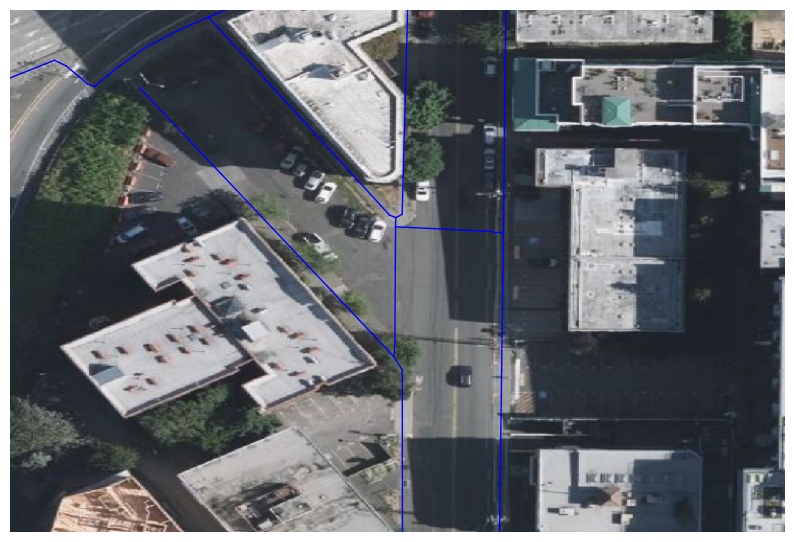

In [20]:
# good: 12, 20, 40, 50, 60, 70, 90
# bad: 30
# disconnected: 22
idx = split_indices[120]
img = Image.open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{idx}/satellite.png')
with open(f'/data/aiclinic/pathways/pathwaybench_seattle/pairs/{idx}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
gt_cache = load_gt_cache(idx, cache_dir)
pred_path = os.path.join(run_dir, f"{idx}_seed{seed}_pred.geojson")
gdf_pred_ll = read_geojson(pred_path, default_crs="EPSG:4326")
gdf_gt_ll = gt_cache["gdf_gt"]  # stored as lon/lat in cache script
gdf_gt_ll.shape, gdf_pred_ll.shape
plot(bbox, img, gdf_gt_ll, gdf_pred_ll)

In [33]:
ds = datasets[0]
ds_name = ds["name"]
pred_root = ds["pred_root"]
split_path = ds["split"]
out_csv = ds["out_csv"]
with open(split_path, "r") as f:
    split_indices = [line.strip() for line in f if line.strip()]
cache_dir = os.path.join(pred_root, f"_gt_cache_{M.PROJ}")
model_name = "swin_tiny"
tag = "grpo"
seed = 0
model_dir = os.path.join(pred_root, model_name)
tag_dir = os.path.join(model_dir, tag)
run_dir = os.path.join(tag_dir, f"seed_{seed}")

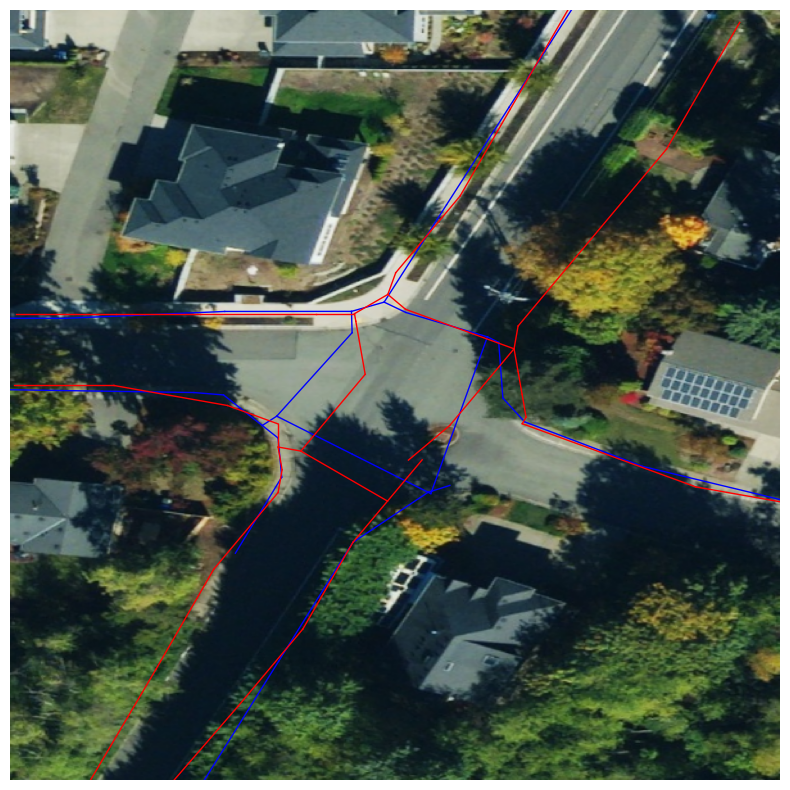

In [38]:
idx = split_indices[20]
img = Image.open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/satellite.png')
with open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
gt_cache = load_gt_cache(idx, cache_dir)
pred_path = os.path.join(run_dir, f"{idx}_seed{seed}_pred.geojson")
gdf_pred_ll = read_geojson(pred_path, default_crs="EPSG:4326")
gdf_gt_ll = gt_cache["gdf_gt"]  # stored as lon/lat in cache script
gdf_gt_ll.shape, gdf_pred_ll.shape
plot(bbox, img, gdf_gt_ll, gdf_pred_ll)

In [45]:
from shapely.geometry import LineString
def norm_xy_to_lonlat(xy, bbox):
    x, y = float(xy[0]), float(xy[1])
    min_lon, max_lon, min_lat, max_lat = bbox
    lon = min_lon + x * (max_lon - min_lon)
    lat = min_lat + y * (max_lat - min_lat)
    return (lon, lat)

def edges_norm_to_lonlat_gdf(edges_xy, bbox, crs="EPSG:4326"):
    geoms = []
    for (u, v) in edges_xy:
        if u is None or v is None:
            continue
        if (u[0] == v[0]) and (u[1] == v[1]):
            continue
        u_ll = norm_xy_to_lonlat(u, bbox)
        v_ll = norm_xy_to_lonlat(v, bbox)
        geoms.append(LineString([u_ll, v_ll]))
    return gpd.GeoDataFrame({"geometry": geoms}, crs=crs)

def gt_graph_to_edges_xy(G):
    return [(tuple(u), tuple(v)) for (u, v) in G.edges]

In [46]:
ds = datasets[2]
ds_name = ds["name"]
pred_root = ds["pred_root"]
split_path = ds["split"]
out_csv = ds["out_csv"]
with open(split_path, "r") as f:
    split_indices = [line.strip() for line in f if line.strip()]
cache_dir = os.path.join(pred_root, f"_gt_cache_{M.PROJ}")
model_name = "swin_tiny"
tag = "grpo"
seed = 0
model_dir = os.path.join(pred_root, model_name)
tag_dir = os.path.join(model_dir, tag)
run_dir = os.path.join(tag_dir, f"seed_{seed}")

In [54]:
idx = split_indices[4]
print(idx)
img = Image.open(f'/data/aiclinic/pathways/pathwaybench_portland/pairs/{idx}/satellite.png')
with open(f'/data/aiclinic/pathways/pathwaybench_portland/pairs/{idx}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
with open(f'/data/aiclinic/pathways/pathwaybench_portland/pairs/{idx}/graph.pickle', 'rb') as f:
    G = pickle.load(f)

00028389_00000002_00000000


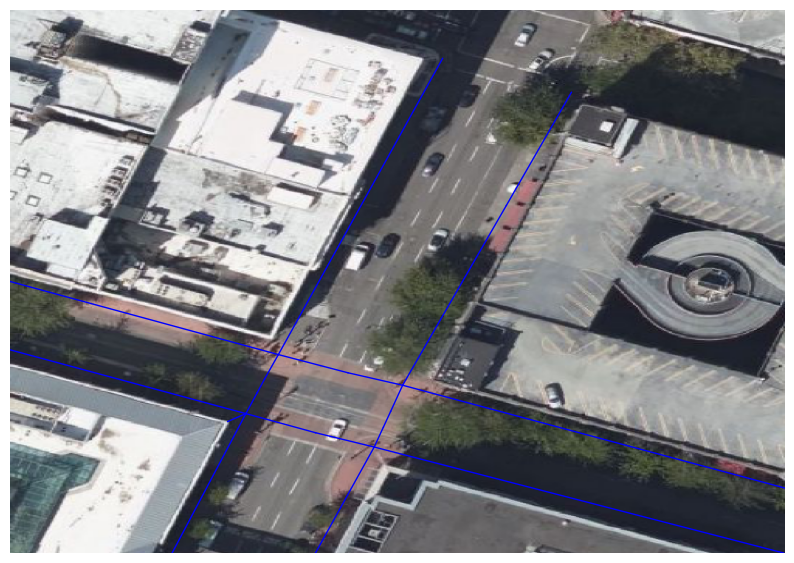

In [55]:
gt_edges_xy = gt_graph_to_edges_xy(G)
gt_gdf = edges_norm_to_lonlat_gdf(gt_edges_xy, bbox, crs="EPSG:4326")
plot(bbox, img, gt_gdf, gt_gdf)